In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

df = pd.read_csv("cardio_train.csv", sep=";")

print("Dataset Shape:", df.shape)

display(df.head())

print(df.columns.tolist())

display(df.dtypes.to_frame("dtype"))

print(df.memory_usage(deep=True).sum() / 1024, "KB")

df.info()

display(df.describe().T)

Dataset Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.00,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.00,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.00,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.00,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.00,100,60,1,1,0,0,0,0


['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


,dtype
id,int64
age,int64
gender,int64
height,int64
weight,float64
ap_hi,int64
ap_lo,int64
cholesterol,int64
gluc,int64
smoke,int64


7109.50390625 KB
<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


,count,mean,std,min,25%,50%,75%,max
id,70000.00,49972.42,28851.30,0.00,25006.75,50001.50,74889.25,99999.00
age,70000.00,19468.87,2467.25,10798.00,17664.00,19703.00,21327.00,23713.00
gender,70000.00,1.35,0.48,1.00,1.00,1.00,2.00,2.00
height,70000.00,164.36,8.21,55.00,159.00,165.00,170.00,250.00
weight,70000.00,74.21,14.40,10.00,65.00,72.00,82.00,200.00
ap_hi,70000.00,128.82,154.01,-150.00,120.00,120.00,140.00,16020.00
ap_lo,70000.00,96.63,188.47,-70.00,80.00,80.00,90.00,11000.00
cholesterol,70000.00,1.37,0.68,1.00,1.00,1.00,2.00,3.00
gluc,70000.00,1.23,0.57,1.00,1.00,1.00,1.00,3.00
smoke,70000.00,0.09,0.28,0.00,0.00,0.00,0.00,1.00


In [14]:
identifier_columns = ["id"] 
numerical_columns = ["age", "height", "weight","ap_hi","ap_lo"]
binary_cols = ['smoke', 'alco', 'active', 'cardio']
category_cols = ["gender", "cholesterol", "gluc"]

In [15]:
df.isnull().sum()

df.duplicated().sum()

df["id"].duplicated().sum()

np.int64(0)

In [16]:
for col in binary_cols:
    print(df[col].value_counts(dropna=False).sort_index())

smoke
0    63831
1     6169
Name: count, dtype: int64
alco
0    66236
1     3764
Name: count, dtype: int64
active
0    13739
1    56261
Name: count, dtype: int64
cardio
0    35021
1    34979
Name: count, dtype: int64


In [17]:

categorical_columns = {
    'gender': [1, 2],
    'cholesterol': [1, 2, 3],
    'gluc': [1, 2, 3],
    'smoke': [0, 1],
    'alco': [0, 1],
    'active': [0, 1],
    'cardio': [0, 1]
}

for col, valid_values in categorical_columns.items():
    invalid = df.loc[~df[col].isin(valid_values), col]
    print(f"{col}: {len(invalid)} invalid values")

print("\nAge in days:")
print("Minimum:", df['age'].min())
print("Maximum:", df['age'].max())
print("Negative ages:", (df['age'] < 0).sum())


gender: 0 invalid values
cholesterol: 0 invalid values
gluc: 0 invalid values
smoke: 0 invalid values
alco: 0 invalid values
active: 0 invalid values
cardio: 0 invalid values

Age in days:
Minimum: 10798
Maximum: 23713
Negative ages: 0


In [18]:
print("\nHeight below 100 or above 220 cm:")
print(((df['height'] < 100) | (df['height'] > 220)).sum())

print("\nWeight below 30 kg:")
print((df['weight'] < 30).sum())

print("\nSystolic BP <= 0:")
print((df['ap_hi'] <= 0).sum())

print("\nSystolic BP > 300:")
print((df['ap_hi'] > 300).sum())

print("\nDiastolic BP <= 0:")
print((df['ap_lo'] <= 0).sum())

print("\nDiastolic BP > 200:")
print((df['ap_lo'] > 200).sum())

print("\nSystolic BP <= diastolic BP:")
print((df['ap_hi'] <= df['ap_lo']).sum())



Height below 100 or above 220 cm:
30

Weight below 30 kg:
7

Systolic BP <= 0:
7

Systolic BP > 300:
40

Diastolic BP <= 0:
22

Diastolic BP > 200:
953

Systolic BP <= diastolic BP:
1236


In [19]:
print("Suspicious heights:")
display(
    df.loc[
        (df['height'] < 100) | (df['height'] > 220),
        'height'
    ].value_counts().sort_index()
)


Suspicious heights:


height
55     1
57     1
59     1
60     1
64     1
65     2
66     1
67     3
68     2
70     3
71     1
72     1
74     1
75     2
76     1
80     1
81     1
91     1
96     1
97     1
98     1
99     1
250    1
Name: count, dtype: int64

In [20]:

suspicious_height = df.loc[
    (df['height'] < 100) | (df['height'] > 220),
    ['id', 'age', 'gender', 'height', 'weight',
     'ap_hi', 'ap_lo', 'cardio']
]

print(suspicious_height.to_string())

          id    age  gender  height  weight  ap_hi  ap_lo  cardio
224      309  21800       2      76   55.00    120     80       0
6486    9223  21220       1     250   86.00    140    100       1
7598   10843  14661       2      70   72.00    120      8       0
8171   11662  17646       2      97  170.00    160    100       1
12770  18218  19594       1      75  168.00    120     80       1
13265  18928  22456       2      71   68.00    120     80       0
14323  20459  22005       1      67   57.00    120     90       1
15167  21686  15812       1      70   68.00    120     80       0
16699  23859  19680       2      74   98.00    140     90       1
17277  24690  17530       1      98   45.00     12     80       0
22542  32207  14538       1      68   65.00    100     60       0
22723  32456  23386       1      55   81.00    130     90       1
23913  34186  19074       1      81  156.00    140     90       0
27384  39156  15292       1      80  178.00    140     90       1
27603  394

• Height 250 cm: Highly suspicious value, most likely a recording error.
• Heights from 55 to 99 cm: Unusually low given the recorded age range (approx. 40–64 years) in this dataset.
• Blood pressure: Some rows also contain unrealistic blood pressure values, but this is a separate issue that will be addressed during the blood pressure columns analysis.

In [21]:

df['height_suspicious'] = (
    (df['height'] < 100) |
    (df['height'] > 220)
)

print("Suspicious height records:",
      df['height_suspicious'].sum())


Suspicious height records: 30


In [22]:
print("Weights below 30 kg:")
print(
    df.loc[df['weight'] < 30, 'weight']
      .value_counts().sort_index()
)

Weights below 30 kg:
weight
10.00    1
11.00    1
21.00    1
22.00    1
23.00    1
28.00    1
29.00    1
Name: count, dtype: int64


In [23]:
suspicious_weight = df.loc[
    df['weight'] < 30,
    ['id', 'age', 'gender', 'height', 'weight',
     'ap_hi', 'ap_lo', 'cardio']
]

print(suspicious_weight.to_string())


          id    age  gender  height  weight  ap_hi  ap_lo  cardio
26806  38312  23284       1     157   23.00    110     80       0
29488  42156  20408       2     177   22.00    120     80       0
33817  48318  21582       2     178   11.00    130     90       1
34276  48976  14664       2     128   28.00    120     80       0
57858  82567  18804       2     165   10.00    180   1100       1
60188  85931  21855       1     162   21.00    120     80       1
60699  86650  18875       1     171   29.00    110     70       1


All seven cases require review, especially the 10 kg and 11 kg weights for individuals recorded with heights exceeding 160 cm. However, we cannot definitively conclude that every value is a recording error based solely on the data.

In [24]:
df['weight_suspicious'] = df['weight'] < 30

print("Suspicious weight records:",
      df['weight_suspicious'].sum())


Suspicious weight records: 7


In [25]:
print("\nSystolic BP <= 0:")
print(
    df.loc[df['ap_hi'] <= 0, 'ap_hi']
      .value_counts().sort_index()
)


Systolic BP <= 0:
ap_hi
-150    1
-140    1
-120    2
-115    1
-100    2
Name: count, dtype: int64


In [26]:

suspicious_systolic = df.loc[
    df['ap_hi'] <= 0,
    ['id', 'age', 'gender', 'height', 'weight',
     'ap_hi', 'ap_lo', 'cardio']
]

print(suspicious_systolic.to_string())

          id    age  gender  height  weight  ap_hi  ap_lo  cardio
4607    6525  15281       1     165   78.00   -100     80       0
16021  22881  22108       2     161   90.00   -115     70       0
20536  29313  15581       1     153   54.00   -100     70       0
23988  34295  18301       1     162   74.00   -140     90       1
25240  36025  14711       2     168   50.00   -120     80       1
35040  50055  23325       2     168   59.00   -150     80       1
46627  66571  23646       2     160   59.00   -120     80       0


In [27]:
df['ap_hi_invalid'] = df['ap_hi'] <= 0

print("Invalid systolic BP records:",
      df['ap_hi_invalid'].sum())

Invalid systolic BP records: 7


In [28]:
print("\nSystolic BP > 300:")
print(
    df.loc[df['ap_hi'] > 300, 'ap_hi']
      .value_counts().sort_index()
)


Systolic BP > 300:
ap_hi
309      1
401      1
701      1
806      1
902      1
906      6
907      3
909      1
960      1
1110     1
1130     1
1202     1
1205     1
1300     2
1400     3
1409     1
1420     2
1500     1
1620     1
2000     1
11020    1
11500    1
13010    2
14020    4
16020    1
Name: count, dtype: int64


In [29]:
high_systolic = df.loc[
    df['ap_hi'] > 300,
    ['id', 'age', 'gender', 'height', 'weight',
     'ap_hi', 'ap_lo', 'cardio']
]

print(high_systolic.to_string())

          id    age  gender  height  weight  ap_hi  ap_lo  cardio
1876    2654  15116       1     160   60.00    902     60       0
2014    2845  22712       2     167   59.00    906      0       0
4817    6822  14425       1     168   63.00    909     60       0
7763   11089  21032       1     175   80.00  11500     90       1
8915   12710  18870       1     164   75.00   1420     80       1
9557   13616  22659       1     155   87.00    701    110       1
13895  19827  15996       1     168   72.00   1500     80       1
17713  25314  22398       2     163   50.00    907     70       1
23867  34120  16131       1     161   92.00    906      0       1
25464  36339  15835       2     169   75.00  14020     80       1
25519  36414  21361       1     169   71.00  14020     80       1
25780  36793  18304       1     157   83.00   1400     80       1
28147  40239  19700       2     175   87.00   1620     80       1
29665  42410  17548       1     154   65.00    907     70       0
31783  454

In [46]:
df['ap_hi_extreme'] = df['ap_hi'] > 300

print("Extreme systolic BP records:",
      df['ap_hi_extreme'].sum())


Extreme systolic BP records: 40


In [30]:
print("\nDiastolic BP <= 0:")
print(
    df.loc[df['ap_lo'] <= 0, 'ap_lo']
      .value_counts().sort_index()
)


Diastolic BP <= 0:
ap_lo
-70     1
 0     21
Name: count, dtype: int64


In [31]:
suspicious_diastolic = df.loc[
    df['ap_lo'] <= 0,
    ['age', 'gender', 'height', 'weight',
     'ap_hi', 'ap_lo', 'cardio']
]

print(suspicious_diastolic.to_string(index=False))


  age  gender  height  weight  ap_hi  ap_lo  cardio
22712       2     167   59.00    906      0       0
14965       2     150   60.00    130      0       0
20457       1     156   50.00    138      0       1
18226       1     164   78.00    138      0       0
21182       2     166   68.00    149      0       1
16131       1     161   92.00    906      0       1
17952       2     176   73.00     12      0       0
23396       2     180   73.00    140      0       1
16070       1     170   64.00    907      0       0
23208       2     170   81.00    148      0       0
20322       1     162   50.00    309      0       0
20970       1     154   41.00    806      0       0
17988       2     176   69.00    906      0       0
18802       1     164   78.00    108      0       0
19597       2     165   70.00    140      0       0
19012       1     160   84.00    121      0       1
21919       1     155   66.00     13      0       0
15268       1     164   70.00    120      0       0
22571       

In [32]:
df['ap_lo_invalid'] = df['ap_lo'] <= 0

print("Invalid diastolic BP records:",
      df['ap_lo_invalid'].sum())


Invalid diastolic BP records: 22


In [33]:
print("Diastolic BP > 200:")
print(
    df.loc[df['ap_lo'] > 200, 'ap_lo']
      .value_counts().sort_index()
)

Diastolic BP > 200:
ap_lo
585      1
602      1
700      1
708      2
709      2
        ..
9011     2
9100     1
9800     1
10000    3
11000    1
Name: count, Length: 62, dtype: int64


In [34]:
bp_order_issues = df.loc[
    df['ap_hi'] <= df['ap_lo'],
    ['age', 'gender', 'height', 'weight',
     'ap_hi', 'ap_lo', 'cardio']
]

print(bp_order_issues.to_string(index=False))

print("\nNumber of records:", len(bp_order_issues))

  age  gender  height  weight  ap_hi  ap_lo  cardio
17489       2     183   98.00    160   1100       1
21932       2     157   60.00    160   1000       1
18217       1     150   83.00    140    800       1
23407       1     176   63.00    160   1000       1
18704       1     154   81.00    140   1000       1
15226       1     150   95.00    150   1033       1
19099       1     156   65.00    120    150       0
20430       2     173  101.00    200   1000       1
21281       1     168   78.00     14     90       1
18963       1     165   92.00    140   1000       1
20457       2     169   68.00     70    110       0
18190       1     166   57.00    190   1100       1
21842       1     156   72.00    180   1000       1
23407       2     170   74.00    140   1000       1
17405       2     170   84.00    150   1100       1
21867       2     175   70.00     14     90       1
18225       1     172   65.00     11     80       0
21043       2     168   82.00    160   1000       1
15906       

Extremely High Diastolic BP (ap_lo): Presence of implausible values such as 1000, 1100, and 1033, which are highly likely attributable to data entry errors.

Systolic BP Lower Than Diastolic (ap_hi <= ap_lo): Recorded cases where systolic pressure is lower than diastolic pressure (e.g., 70 / 110), representing a physiologically invalid pattern that requires handling.

Unrealistically Low Systolic Readings (ap_hi): Presence of extreme low outliers such as 11 and 14, which are completely unrealistic for standard systolic blood pressure readings.

In [35]:
extreme_ap_lo = df['ap_lo'] > 200

print("Diastolic BP above 200:",
      extreme_ap_lo.sum())

bp_order_issue = df['ap_hi'] <= df['ap_lo']

print("Systolic BP <= diastolic BP:",
      bp_order_issue.sum())

low_ap_hi = df['ap_hi'] < 60

print("Systolic BP below 60:",
      low_ap_hi.sum())

Diastolic BP above 200: 953
Systolic BP <= diastolic BP: 1236
Systolic BP below 60: 188


In [36]:
print("Systolic BP <= diastolic BP:")
print(
    df.loc[
        df['ap_hi'] <= df['ap_lo'],
        ['ap_hi', 'ap_lo']
    ].value_counts().head(20)
)

Systolic BP <= diastolic BP:
ap_hi  ap_lo
150    1000     197
160    1000     169
140    1000     141
12     80        67
180    1000      47
160    1100      46
170    1000      42
150    1100      31
130    1000      28
180    1100      28
80     120       24
140    1100      19
190    1000      17
14     90        16
170    1100      15
11     70        14
90     140        9
120    1000       8
90     130        8
70     110        7
Name: count, dtype: int64


In [37]:
print(
    df.loc[df['ap_lo'] > 200, 'ap_lo']
      .value_counts()
      .sort_index()
      .to_string()
)

print("\nMinimum:", df.loc[df['ap_lo'] > 200, 'ap_lo'].min())
print("Maximum:", df.loc[df['ap_lo'] > 200, 'ap_lo'].max())


ap_lo
585        1
602        1
700        1
708        2
709        2
710        2
800        5
801        2
802        1
809        3
810        1
820        1
850        2
870        1
880        1
900        2
901        1
902        2
910        1
1000     666
1001       8
1002       1
1003       2
1007       1
1008       4
1011       2
1022       1
1033       2
1044       1
1077       1
1088       2
1100     156
1101       1
1110      11
1111       1
1120       5
1125       1
1139       1
1140       1
1177       2
1200      21
1211       1
1400       2
1900       2
2088       1
5700       2
6800       1
7099       1
7100       1
8000       2
8044       1
8077       1
8079       1
8099       3
8100       1
8200       1
8500       1
9011       2
9100       1
9800       1
10000      3
11000      1

Minimum: 585
Maximum: 11000


In [38]:
extreme_records = df.loc[
    df['ap_lo'] > 200,
    ['age', 'gender', 'height', 'weight',
     'ap_hi', 'ap_lo', 'cardio']
]

print("Most frequent values:")
print(extreme_records['ap_lo'].value_counts().head(10))

print("\nExamples where ap_lo = 1000:")
print(
    extreme_records.loc[
        extreme_records['ap_lo'] == 1000
    ].head(10).to_string(index=False)
)


Most frequent values:
ap_lo
1000     666
1100     156
1200      21
1110      11
1001       8
800        5
1120       5
1008       4
10000      3
8099       3
Name: count, dtype: int64

Examples where ap_lo = 1000:
  age  gender  height  weight  ap_hi  ap_lo  cardio
21932       2     157   60.00    160   1000       1
23407       1     176   63.00    160   1000       1
18704       1     154   81.00    140   1000       1
20430       2     173  101.00    200   1000       1
18963       1     165   92.00    140   1000       1
21842       1     156   72.00    180   1000       1
23407       2     170   74.00    140   1000       1
21043       2     168   82.00    160   1000       1
21107       2     169   76.00    140   1000       1
20344       1     152   55.00    140   1000       1


In [39]:
low_systolic = df.loc[df['ap_hi'] < 60, 'ap_hi']

print("Value counts:")
print(low_systolic.value_counts().sort_index().to_string())

print("\nMinimum:", low_systolic.min())
print("Maximum:", low_systolic.max())
print("Total records:", len(low_systolic))


Value counts:
ap_hi
-150     1
-140     1
-120     2
-115     1
-100     2
 1       2
 7       1
 10      7
 11     28
 12     76
 13     15
 14     29
 15     12
 16      3
 17      3
 20      4
 24      1

Minimum: -150
Maximum: 24
Total records: 188


In [40]:
negative_ap_hi = df['ap_hi'] < 0
low_positive_ap_hi = (
    (df['ap_hi'] > 0) &
    (df['ap_hi'] < 60)
)

print("Negative systolic BP:", negative_ap_hi.sum())
print("Positive systolic BP below 60:", low_positive_ap_hi.sum())


Negative systolic BP: 7
Positive systolic BP below 60: 181


cardio
0    35021
1    34979
Name: count, dtype: int64
cardio
0   50.03
1   49.97
Name: proportion, dtype: float64


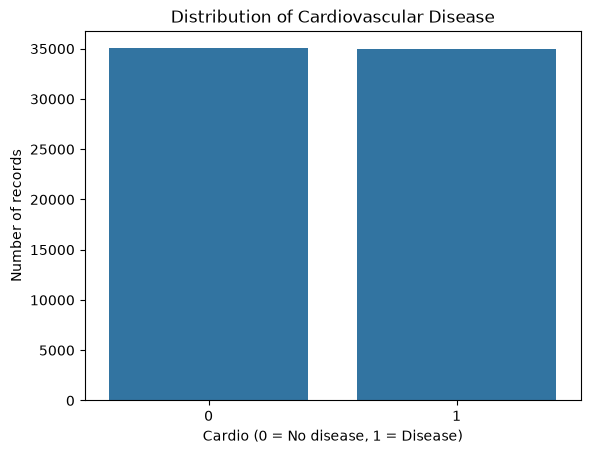

In [41]:
print(df["cardio"].value_counts())

print(
    df["cardio"].value_counts(normalize=True).mul(100).round(2)
)

sns.countplot(data=df, x="cardio")
plt.title("Distribution of Cardiovascular Disease")
plt.xlabel("Cardio (0 = No disease, 1 = Disease)")
plt.ylabel("Number of records")
plt.show()

In [42]:
df['age_years'] = (df['age'] / 365.25).round(1)

print(df['age_years'].describe())

count   70000.00
mean       53.30
std         6.76
min        29.60
25%        48.40
50%        53.90
75%        58.40
max        64.90
Name: age_years, dtype: float64


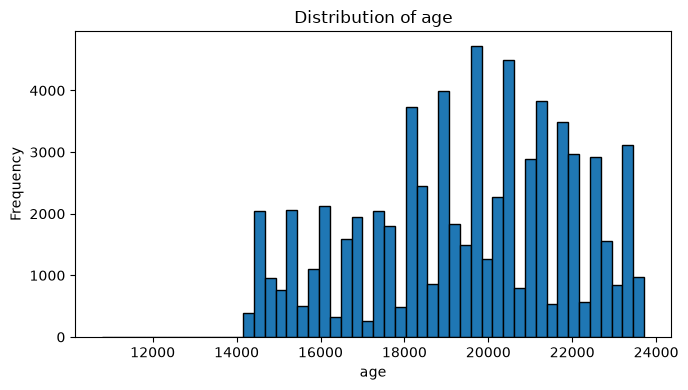

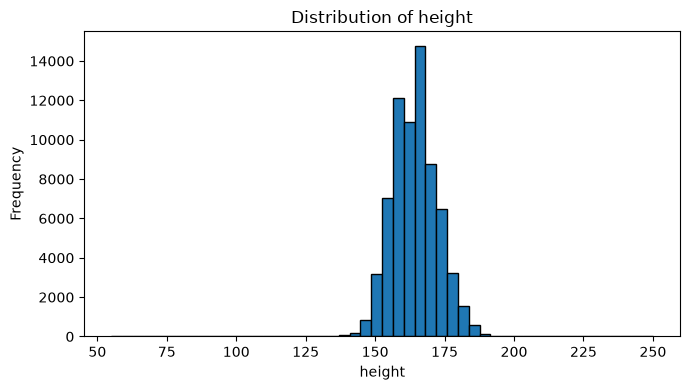

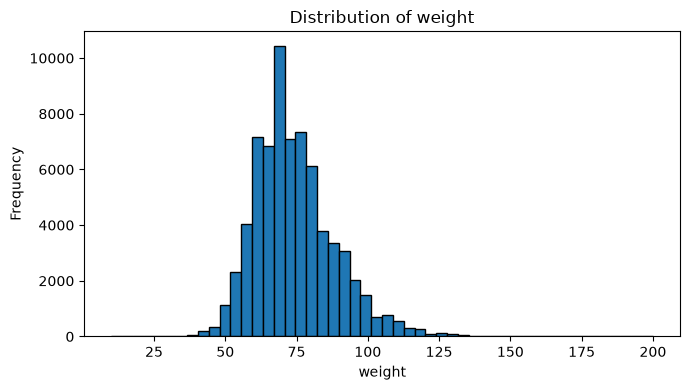

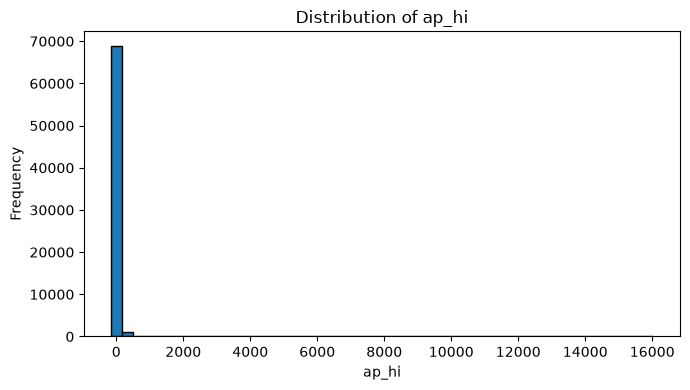

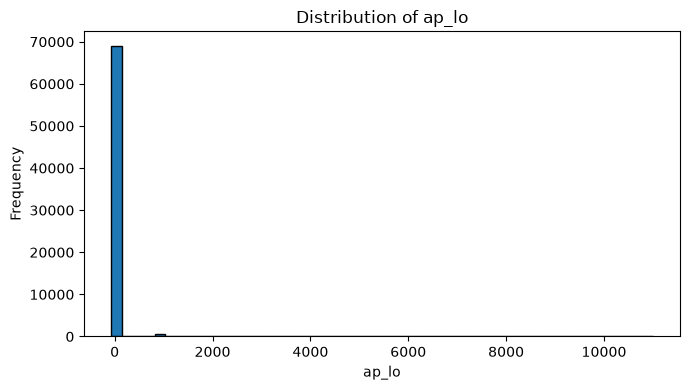

In [45]:
for col in numerical_columns:
    plt.figure(figsize=(7, 4))
    plt.hist(df[col], bins=50, edgecolor='black')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()


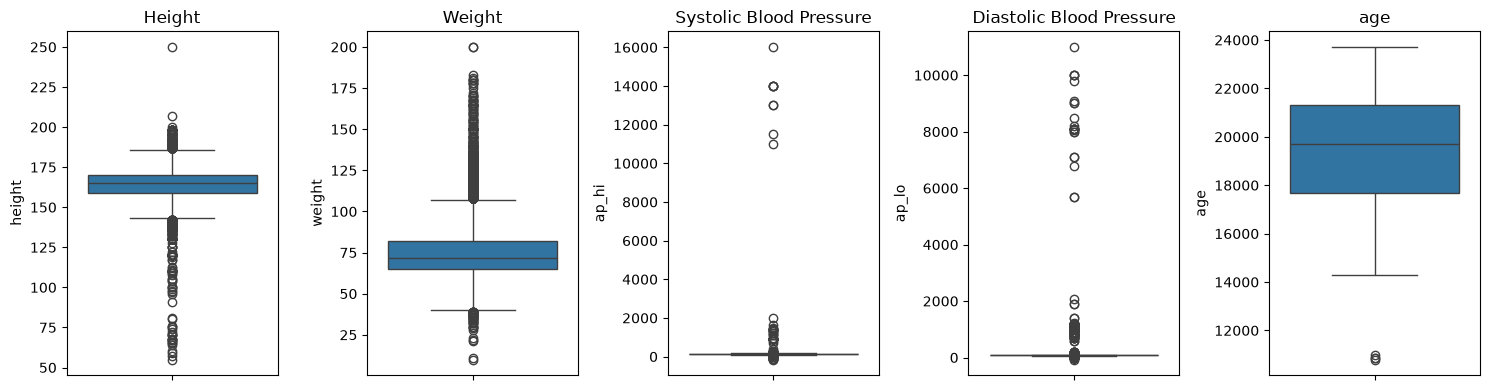

In [46]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

sns.boxplot(y=df["height"], ax=axes[0])
axes[0].set_title("Height")

sns.boxplot(y=df["weight"], ax=axes[1])
axes[1].set_title("Weight")

sns.boxplot(y=df["ap_hi"], ax=axes[2])
axes[2].set_title("Systolic Blood Pressure")

sns.boxplot(y=df["ap_lo"], ax=axes[3])
axes[3].set_title("Diastolic Blood Pressure")

sns.boxplot(y=df["age"], ax=axes[4])
axes[4].set_title("age")

plt.tight_layout()
plt.show()

In [15]:
for i in numerical_columns:
    mean = df[i].mean()
    median = df[i].median()
    skewness = df[i].skew()
    print(f"{i} mean = {mean}")
    print(f"{i} median = {median}")
    print(f"{i} median = {median}")
    print("\n")



age mean = 19468.865814285713
age median = 19703.0
age median = 19703.0


height mean = 164.35922857142856
height median = 165.0
height median = 165.0


weight mean = 74.20569
weight median = 72.0
weight median = 72.0


ap_hi mean = 128.8172857142857
ap_hi median = 120.0
ap_hi median = 120.0


ap_lo mean = 96.63041428571428
ap_lo median = 80.0
ap_lo median = 80.0




,feature,Q1,Q3,IQR,lower_bound,upper_bound,potential_outliers
0,age,17664.00,21327.00,3663.00,12169.50,26821.50,4
1,height,159.00,170.00,11.00,142.50,186.50,519
2,weight,65.00,82.00,17.00,39.50,107.50,1819
3,ap_hi,120.00,140.00,20.00,90.00,170.00,1435
4,ap_lo,80.00,90.00,10.00,65.00,105.00,4632


C:\Users\mg050\AppData\Local\Temp\ipykernel_10196\4074449832.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


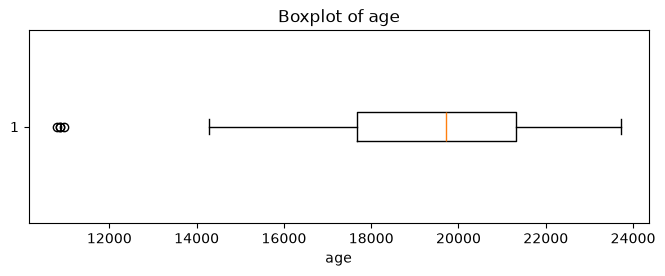

C:\Users\mg050\AppData\Local\Temp\ipykernel_10196\4074449832.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


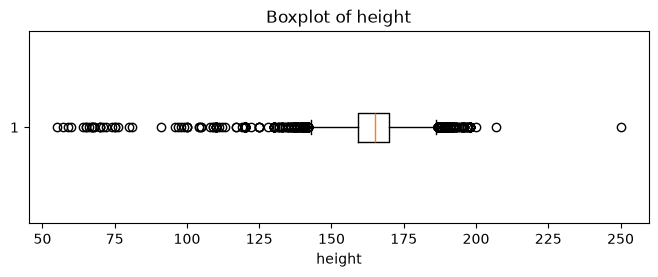

C:\Users\mg050\AppData\Local\Temp\ipykernel_10196\4074449832.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


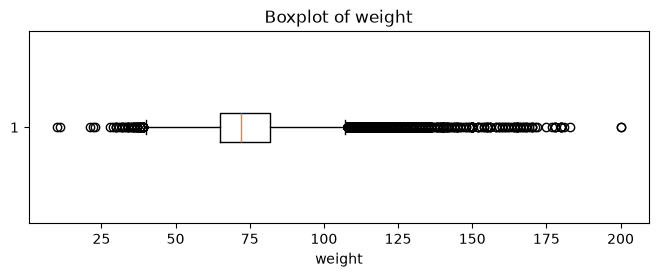

C:\Users\mg050\AppData\Local\Temp\ipykernel_10196\4074449832.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


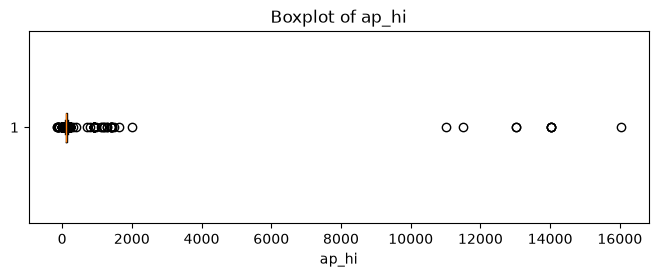

C:\Users\mg050\AppData\Local\Temp\ipykernel_10196\4074449832.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


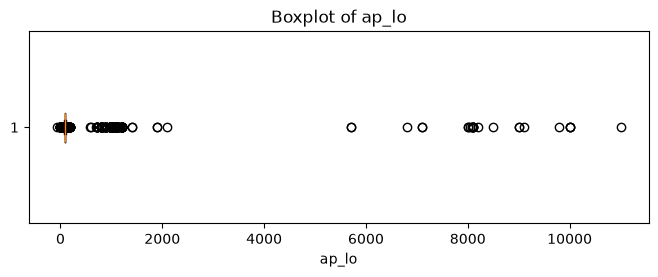

In [48]:
outlier_rows = []

for col in ["age", "height", "weight","ap_hi", "ap_lo"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_rows.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "potential_outliers": count
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

for col in ["age", "height", "weight","ap_hi", "ap_lo"]:
    plt.figure(figsize=(8, 2.5))
    plt.boxplot(df[col].dropna(), vert=False )
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

In [13]:

outlier_summary["Q2 (Median)"] = [
    df[col].quantile(0.50)
    for col in ["age", "height", "weight", "ap_hi", "ap_lo"]
]

outlier_summary["outlier_percentage"] = (
    outlier_summary["potential_outliers"] / len(df) * 100
)

display(
    outlier_summary[
        [
            "feature", "Q1", "Q2 (Median)", "Q3", "IQR",
            "lower_bound", "upper_bound",
            "potential_outliers", "outlier_percentage"
        ]
    ].round(2)
)

,feature,Q1,Q2 (Median),Q3,IQR,lower_bound,upper_bound,potential_outliers,outlier_percentage
0,age,17664.00,19703.00,21327.00,3663.00,12169.50,26821.50,4,0.01
1,height,159.00,165.00,170.00,11.00,142.50,186.50,519,0.74
2,weight,65.00,72.00,82.00,17.00,39.50,107.50,1819,2.60
3,ap_hi,120.00,120.00,140.00,20.00,90.00,170.00,1435,2.05
4,ap_lo,80.00,80.00,90.00,10.00,65.00,105.00,4632,6.62


In [14]:
for col in ["age", "height", "weight", "ap_hi", "ap_lo"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df.loc[
        (df[col] < lower) | (df[col] > upper), col
    ]

    print(f"\n=== {col} ===")
    print("Lowest potential outliers:")
    print(outliers.sort_values().head(10).to_list())
    print("Highest potential outliers:")
    print(outliers.sort_values(ascending=False).head(10).to_list())


=== age ===
Lowest potential outliers:
[10798, 10859, 10878, 10964]
Highest potential outliers:
[10964, 10878, 10859, 10798]

=== height ===
Lowest potential outliers:
[55, 57, 59, 60, 64, 65, 65, 66, 67, 67]
Highest potential outliers:
[250, 207, 200, 198, 198, 198, 198, 198, 198, 198]

=== weight ===
Lowest potential outliers:
[10.0, 11.0, 21.0, 22.0, 23.0, 28.0, 29.0, 30.0, 30.0, 30.0]
Highest potential outliers:
[200.0, 200.0, 183.0, 181.0, 180.0, 180.0, 180.0, 180.0, 178.0, 178.0]

=== ap_hi ===
Lowest potential outliers:
[-150, -140, -120, -120, -115, -100, -100, 1, 1, 7]
Highest potential outliers:
[16020, 14020, 14020, 14020, 14020, 13010, 13010, 11500, 11020, 2000]

=== ap_lo ===
Lowest potential outliers:
[-70, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Highest potential outliers:
[11000, 10000, 10000, 10000, 9800, 9100, 9011, 9011, 8500, 8200]
